# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

**Nama:** Rayyan Muhtar Ali
**NRP:** 5054251051
**Mata Kuliah:** Penambangan Data

**Dataset:** Credit Card Fraud Detection (Kaggle), file `creditcard.csv`, 284.807 baris dan 31 kolom.
Link: https://www.kaggle.com/mlg-ulb/creditcardfraud

Datanya berisi transaksi kartu kredit pemegang kartu di Eropa selama dua hari di bulan September 2013. Fitur `V1` sampai `V28` sudah berupa hasil PCA (fitur aslinya dirahasiakan), sisanya `Time` (detik sejak transaksi pertama) dan `Amount` (nominal transaksi). Kolom `Class` bernilai 1 kalau transaksinya fraud dan 0 kalau normal.

Masalah utamanya ada di proporsi kelas: fraud cuma sekitar 0,17% dari seluruh transaksi. Di notebook ini saya bangun model Random Forest, lalu membandingkan hasilnya tanpa penanganan imbalance dan dengan tiga cara penanganan (SMOTE, random undersampling, dan class weight). Sebagai pembanding saya juga coba satu model boosting.

> Catatan: dataset tidak ikut diunggah ke repo karena ukurannya sekitar 150 MB. Notebook membaca file dari `../archive/creditcard.csv`.

## 1. Import dan Pemahaman Dataset

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 32)

WARNA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SEED = 42

In [2]:
df = pd.read_csv("../archive/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

In [4]:
df[["Time", "Amount", "V1", "V2", "V3"]].describe().round(2)

,Time,Amount,V1,V2,V3
count,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00,0.00,-0.00
std,47488.15,250.12,1.96,1.65,1.52
min,0.00,0.00,-56.41,-72.72,-48.33
25%,54201.50,5.60,-0.92,-0.60,-0.89
50%,84692.00,22.00,0.02,0.07,0.18
75%,139320.50,77.16,1.32,0.80,1.03
max,172792.00,25691.16,2.45,22.06,9.38


In [5]:
print("Jumlah nilai kosong :", df.isna().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Duplikat yang fraud  :", df[df.duplicated()]["Class"].sum())

Jumlah nilai kosong : 0


Jumlah baris duplikat: 1081


Duplikat yang fraud  : 19


Semua kolom bertipe numerik (30 float dan `Class` integer) dan tidak ada nilai kosong. `Time` berkisar 0 sampai 172.792 detik (sekitar 48 jam), sedangkan `Amount` sangat menceng: mediannya cuma 22, tapi nilai maksimumnya 25.691. Ada 1.081 baris yang persis duplikat, 19 di antaranya fraud.

## 2. Praproses Data

### 2.1 Distribusi kelas

In [6]:
jumlah = df["Class"].value_counts().sort_index()
persen = df["Class"].value_counts(normalize=True).sort_index() * 100
distribusi = pd.DataFrame({"Jumlah": jumlah, "Persen (%)": persen.round(3)})
distribusi.index = ["Normal (0)", "Fraud (1)"]
distribusi

,Jumlah,Persen (%)
Normal (0),284315,99.827
Fraud (1),492,0.173


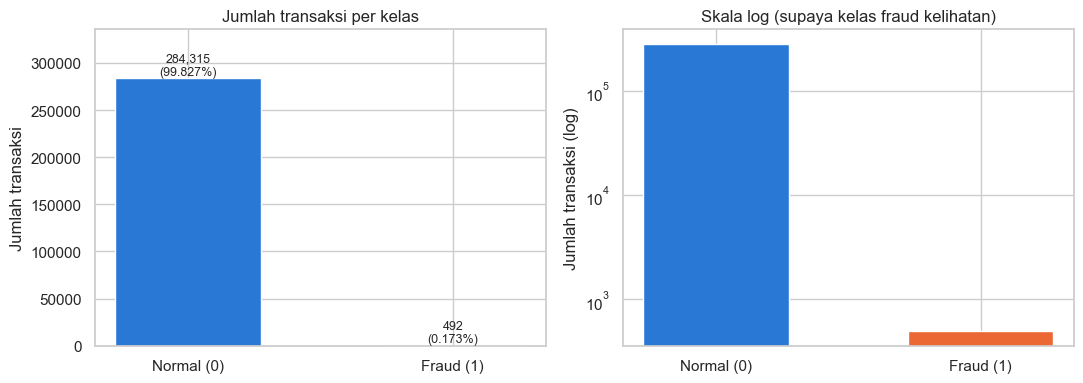

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(distribusi.index, distribusi["Jumlah"], color=WARNA[:2], width=0.55)
for i, (n, p) in enumerate(zip(distribusi["Jumlah"], distribusi["Persen (%)"])):
    axes[0].text(i, n, f"{n:,}\n({p:.3f}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Jumlah transaksi per kelas")
axes[0].set_ylabel("Jumlah transaksi")
axes[0].set_ylim(0, distribusi["Jumlah"].max() * 1.18)

axes[1].bar(distribusi.index, distribusi["Jumlah"], color=WARNA[:2], width=0.55)
axes[1].set_yscale("log")
axes[1].set_title("Skala log (supaya kelas fraud kelihatan)")
axes[1].set_ylabel("Jumlah transaksi (log)")

plt.tight_layout()
plt.show()

Dari 284.807 transaksi, hanya 492 yang fraud (0,173%). Perbandingannya kira-kira 1 fraud untuk setiap 578 transaksi normal. Di grafik skala biasa batang fraud bahkan hampir tidak terlihat, makanya saya tambahkan versi skala log.

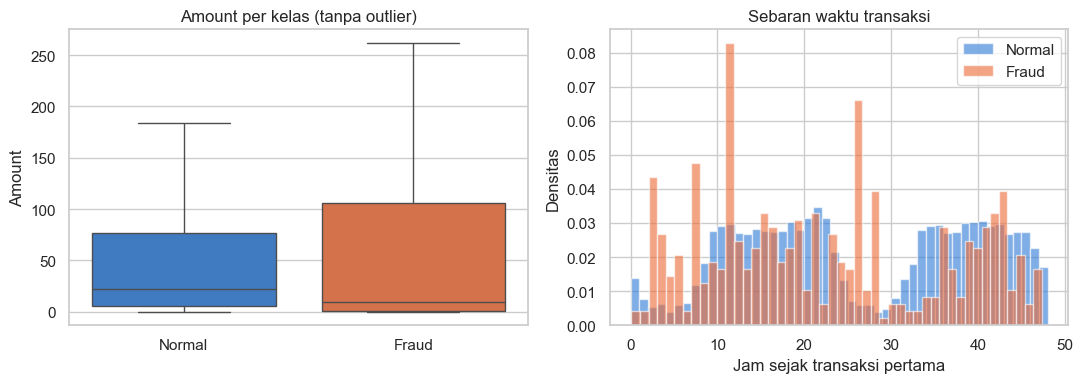

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette=WARNA[:2],
            legend=False, ax=axes[0], showfliers=False)
axes[0].set_xticks([0, 1], ["Normal", "Fraud"])
axes[0].set_xlabel("")
axes[0].set_title("Amount per kelas (tanpa outlier)")

for kelas, warna, label in [(0, WARNA[0], "Normal"), (1, WARNA[1], "Fraud")]:
    jam = df.loc[df["Class"] == kelas, "Time"] / 3600
    axes[1].hist(jam, bins=48, density=True, alpha=0.6, color=warna, label=label)
axes[1].set_title("Sebaran waktu transaksi")
axes[1].set_xlabel("Jam sejak transaksi pertama")
axes[1].set_ylabel("Densitas")
axes[1].legend()

plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe().round(2))

Nominal transaksi fraud ternyata tidak lebih besar dari transaksi normal. Mediannya malah lebih kecil (9,25 dibanding 22), meskipun sebarannya lebih lebar, jadi `Amount` sendirian tidak cukup untuk membedakan fraud. Transaksi normal jelas mengikuti pola siang-malam, dengan penurunan tajam sekitar jam ke-1 sampai 7 dan jam ke-25 sampai 31 (kemungkinan dini hari). Transaksi fraud tidak ikut turun di jam-jam sepi itu, bahkan ada lonjakan di sekitar jam ke-2, ke-11, dan ke-26.

### 2.2 Hapus duplikat dan bagi data latih/uji

Baris duplikat saya buang dulu. Kalau dibiarkan, baris yang sama bisa masuk ke data latih sekaligus data uji, sehingga hasil evaluasi jadi terlalu optimis. Setelah itu data dibagi 80:20 dengan `stratify=y` supaya proporsi fraud di data latih dan data uji tetap sama.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape setelah hapus duplikat:", df.shape)
print(df["Class"].value_counts())

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

pd.DataFrame({
    "Jumlah baris": [len(y_train), len(y_test)],
    "Fraud": [y_train.sum(), y_test.sum()],
    "Persen fraud (%)": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(3)

Shape setelah hapus duplikat: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


,Jumlah baris,Fraud,Persen fraud (%)
Train,226980,378,0.167
Test,56746,95,0.167


`V1` sampai `V28` sudah hasil PCA, jadi skalanya sudah mirip. `Time` dan `Amount` masih dalam satuan aslinya, jadi keduanya saya standarisasi. Random Forest sebenarnya tidak terpengaruh skala, tapi SMOTE memakai jarak antar-tetangga, sehingga skala yang jauh berbeda bisa mendominasi perhitungan jarak. Scaler hanya di-fit pada data latih.

In [10]:
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])
X_train[["Time", "Amount"]].describe().round(2)

,Time,Amount
count,226980.00,226980.00
mean,-0.00,0.00
std,1.00,1.00
min,-2.00,-0.36
25%,-0.86,-0.34
50%,-0.21,-0.27
75%,0.94,-0.04
max,1.64,79.62


### 2.3 Resampling pada data latih

Ada dua teknik resampling yang saya coba, dan keduanya hanya diterapkan ke data latih. Data uji tetap dengan distribusi asli supaya hasil evaluasinya mencerminkan kondisi nyata.

- **SMOTE (oversampling):** membuat sampel fraud sintetis dengan cara interpolasi antara satu sampel fraud dan tetangga terdekatnya, sampai jumlah fraud sama dengan jumlah transaksi normal.
- **Random undersampling:** membuang sebagian besar transaksi normal secara acak sampai jumlahnya sama dengan jumlah fraud.

Teknik ketiga, cost-sensitive learning, tidak mengubah data sama sekali. Caranya lewat parameter `class_weight` di model, dan saya pakai nanti di bagian 3.

In [11]:
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
X_under, y_under = RandomUnderSampler(random_state=SEED).fit_resample(X_train, y_train)

ringkas = pd.DataFrame({
    "Asli": y_train.value_counts(),
    "SMOTE": y_smote.value_counts(),
    "Undersampling": y_under.value_counts(),
}).T
ringkas.columns = ["Normal (0)", "Fraud (1)"]
ringkas["Total"] = ringkas.sum(axis=1)
ringkas

,Normal (0),Fraud (1),Total
Asli,226602,378,226980
SMOTE,226602,226602,453204
Undersampling,378,378,756


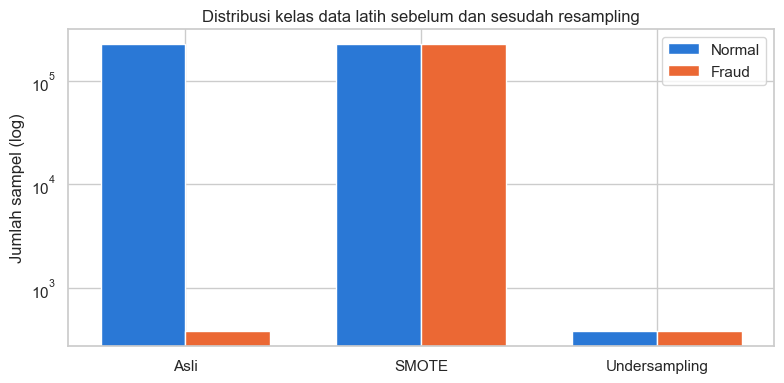

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
posisi = np.arange(len(ringkas))
lebar = 0.36
ax.bar(posisi - lebar / 2, ringkas["Normal (0)"], lebar, color=WARNA[0], label="Normal")
ax.bar(posisi + lebar / 2, ringkas["Fraud (1)"], lebar, color=WARNA[1], label="Fraud")
ax.set_xticks(posisi, ringkas.index)
ax.set_yscale("log")
ax.set_ylabel("Jumlah sampel (log)")
ax.set_title("Distribusi kelas data latih sebelum dan sesudah resampling")
ax.legend()
plt.tight_layout()
plt.show()

SMOTE menambah fraud dari 378 menjadi 226.602 sampel, sehingga data latih membengkak menjadi sekitar 453 ribu baris. Undersampling sebaliknya: data latih tinggal 756 baris (378 + 378), dan lebih dari 99% transaksi normal tidak ikut dipakai.

## 3. Membangun Model Klasifikasi

Model utamanya Random Forest dengan 100 pohon. Supaya perbandingannya adil, semua skenario memakai parameter yang sama; yang berbeda hanya data latih atau bobot kelasnya:

1. **Baseline:** data latih asli tanpa penanganan imbalance
2. **SMOTE:** data latih hasil SMOTE
3. **Undersampling:** data latih hasil random undersampling
4. **Class weight:** data asli, tapi dengan `class_weight="balanced_subsample"`, sehingga kesalahan pada kelas fraud diberi bobot lebih besar di setiap pohon

In [13]:
hasil = {}
model_terlatih = {}

def latih_dan_evaluasi(nama, model, X_fit, y_fit):
    mulai = time.time()
    model.fit(X_fit, y_fit)
    durasi = time.time() - mulai
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    hasil[nama] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob),
        "AUPRC": average_precision_score(y_test, y_prob),
        "Waktu latih (s)": durasi,
    }
    model_terlatih[nama] = (y_pred, y_prob)
    print(f"{nama}  ({len(y_fit):,} baris latih, {durasi:.0f} detik)")
    print(classification_report(y_test, y_pred, digits=4,
                                target_names=["Normal", "Fraud"]))

def rf(**kwargs):
    return RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                  random_state=SEED, **kwargs)

In [14]:
latih_dan_evaluasi("RF Baseline", rf(), X_train, y_train)

RF Baseline  (226,980 baris latih, 15 detik)
              precision    recall  f1-score   support

      Normal     0.9995    1.0000    0.9998     56651
       Fraud     0.9718    0.7263    0.8313        95

    accuracy                         0.9995     56746
   macro avg     0.9857    0.8631    0.9155     56746
weighted avg     0.9995    0.9995    0.9995     56746



In [15]:
latih_dan_evaluasi("RF + SMOTE", rf(), X_smote, y_smote)

RF + SMOTE  (453,204 baris latih, 28 detik)
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     56651
       Fraud     0.9114    0.7579    0.8276        95

    accuracy                         0.9995     56746
   macro avg     0.9555    0.8789    0.9137     56746
weighted avg     0.9994    0.9995    0.9994     56746



In [16]:
latih_dan_evaluasi("RF + Undersampling", rf(), X_under, y_under)

RF + Undersampling  (756 baris latih, 0 detik)
              precision    recall  f1-score   support

      Normal     0.9998    0.9842    0.9919     56651
       Fraud     0.0848    0.8737    0.1546        95

    accuracy                         0.9840     56746
   macro avg     0.5423    0.9289    0.5732     56746
weighted avg     0.9983    0.9840    0.9905     56746



In [17]:
model_cw = rf(class_weight="balanced_subsample")
latih_dan_evaluasi("RF + Class weight", model_cw, X_train, y_train)

RF + Class weight  (226,980 baris latih, 9 detik)
              precision    recall  f1-score   support

      Normal     0.9995    1.0000    0.9997     56651
       Fraud     0.9710    0.7053    0.8171        95

    accuracy                         0.9995     56746
   macro avg     0.9853    0.8526    0.9084     56746
weighted avg     0.9995    0.9995    0.9994     56746



Sebagai pembanding dari keluarga boosting, saya juga melatih `HistGradientBoostingClassifier` (versi gradient boosting di scikit-learn yang cepat untuk data besar), dengan data asli dan data SMOTE.

In [18]:
gb = lambda: HistGradientBoostingClassifier(random_state=SEED)
latih_dan_evaluasi("GB Baseline", gb(), X_train, y_train)
latih_dan_evaluasi("GB + SMOTE", gb(), X_smote, y_smote)

GB Baseline  (226,980 baris latih, 0 detik)
              precision    recall  f1-score   support

      Normal     0.9995    0.9989    0.9992     56651
       Fraud     0.5038    0.6947    0.5841        95

    accuracy                         0.9983     56746
   macro avg     0.7517    0.8468    0.7916     56746
weighted avg     0.9987    0.9983    0.9985     56746



GB + SMOTE  (453,204 baris latih, 2 detik)
              precision    recall  f1-score   support

      Normal     0.9997    0.9988    0.9993     56651
       Fraud     0.5379    0.8211    0.6500        95

    accuracy                         0.9985     56746
   macro avg     0.7688    0.9099    0.8246     56746
weighted avg     0.9989    0.9985    0.9987     56746



## 4. Evaluasi Model

### 4.1 Tabel perbandingan metrik

In [19]:
tabel = pd.DataFrame(hasil).T
format_kolom = {k: "{:.4f}" for k in tabel.columns}
format_kolom["Waktu latih (s)"] = "{:.1f}"
tabel.style.format(format_kolom).highlight_max(
    subset=["Precision", "Recall", "F1-score", "AUC-ROC", "AUPRC"], color="#cfe3f7")

,Accuracy,Precision,Recall,F1-score,AUC-ROC,AUPRC,Waktu latih (s)
RF Baseline,0.9995,0.9718,0.7263,0.8313,0.9239,0.7876,15.1
RF + SMOTE,0.9995,0.9114,0.7579,0.8276,0.9662,0.8040,27.6
RF + Undersampling,0.9840,0.0848,0.8737,0.1546,0.9767,0.6983,0.1
RF + Class weight,0.9995,0.9710,0.7053,0.8171,0.9246,0.7963,8.9
GB Baseline,0.9983,0.5038,0.6947,0.5841,0.7648,0.5278,0.4
GB + SMOTE,0.9985,0.5379,0.8211,0.6500,0.9645,0.7952,2.4


Accuracy semua model di atas 98%, tapi kalau dilihat dari kelas fraud bedanya jauh. RF baseline sebenarnya sudah lumayan, precision 0,972 dan recall 0,726. Jadi kalau model bilang fraud hampir pasti benar, cuma sekitar seperempat fraud masih lolos.

Dengan SMOTE recall naik ke 0,758 dan AUC-ROC dari 0,924 ke 0,966, precision-nya turun sedikit ke 0,911. F1-nya hampir sama dengan baseline (0,828 vs 0,831), tapi AUPRC-nya paling tinggi, 0,804. Undersampling recall-nya paling tinggi (0,874), tapi precision-nya jatuh ke 0,085: dari 979 transaksi yang ditandai fraud, yang benar fraud cuma 83. Wajar, karena model hanya belajar dari 378 transaksi normal.

Class weight hasilnya hampir sama dengan baseline. Dugaan saya karena pohon di Random Forest dibiarkan tumbuh penuh sampai daunnya murni, jadi bobot kelas tidak banyak mengubah prediksi akhirnya. Gradient Boosting dengan parameter default malah lebih lemah dari RF (F1 0,584), tapi di model ini SMOTE kelihatan sekali pengaruhnya: recall naik dari 0,695 ke 0,821 dan AUPRC dari 0,528 ke 0,795.

### 4.2 Confusion matrix

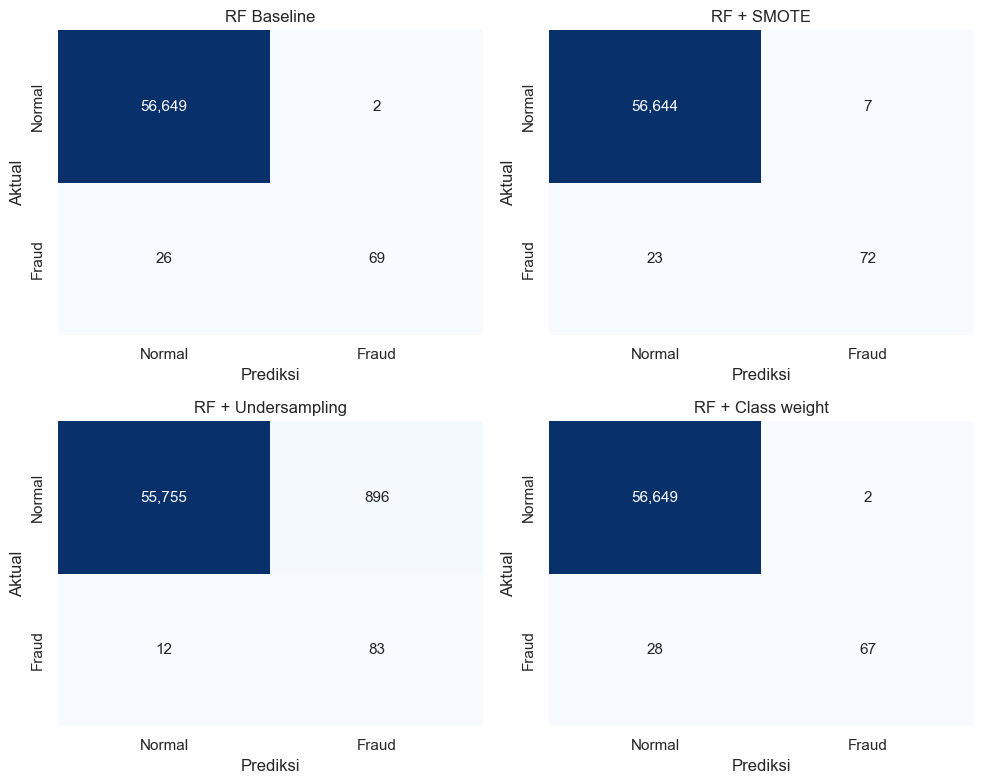

In [20]:
nama_rf = ["RF Baseline", "RF + SMOTE",
           "RF + Undersampling", "RF + Class weight"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, nama in zip(axes.ravel(), nama_rf):
    cm = confusion_matrix(y_test, model_terlatih[nama][0])
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"],
                annot_kws={"size": 11})
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

Confusion matrix memperlihatkan trade-off-nya dengan lebih jelas. Baseline hanya salah menandai 2 transaksi normal, tapi melewatkan 26 dari 95 fraud. SMOTE mengurangi fraud yang lolos menjadi 23, dengan biaya 7 alarm palsu. Undersampling paling sedikit melewatkan fraud (12), tapi menghasilkan 896 alarm palsu; kalau dipakai sungguhan, petugas harus memeriksa sekitar 11 transaksi normal untuk menemukan 1 fraud.

### 4.3 Kurva ROC dan Precision-Recall

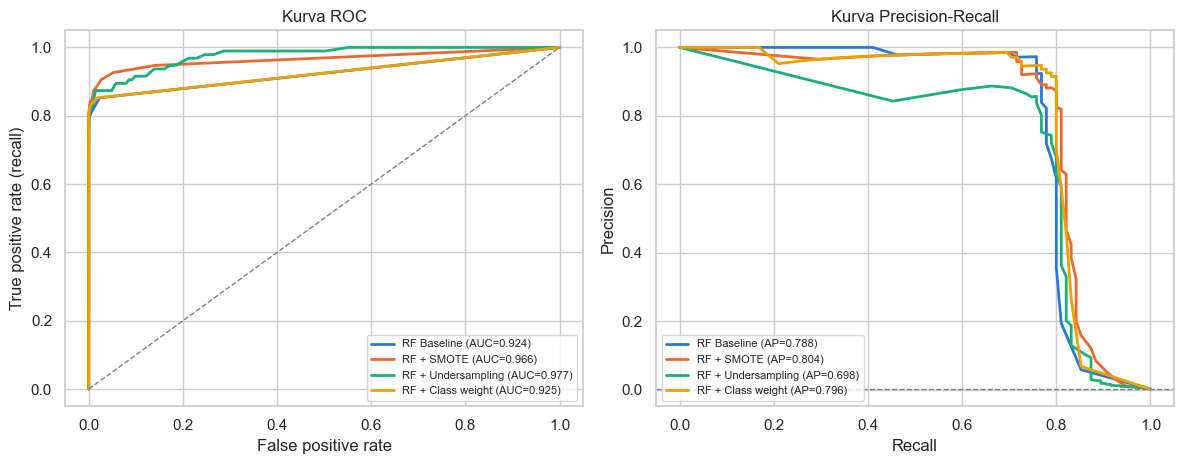

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for nama, warna in zip(nama_rf, WARNA):
    y_prob = model_terlatih[nama][1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    label_roc = f"{nama} (AUC={hasil[nama]['AUC-ROC']:.3f})"
    label_pr = f"{nama} (AP={hasil[nama]['AUPRC']:.3f})"
    axes[0].plot(fpr, tpr, color=warna, lw=2, label=label_roc)
    axes[1].plot(rec, prec, color=warna, lw=2, label=label_pr)

axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("Kurva ROC")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_test.mean(), ls="--", color="grey", lw=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Kurva Precision-Recall")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

Di kurva ROC, keempat model terlihat sangat bagus (AUC antara 0,92 dan 0,98) karena jumlah transaksi normal yang sangat banyak membuat false positive rate tetap kecil. Kurva Precision-Recall lebih jujur: garis putus-putus di bawah adalah baseline acak (0,0017). Kurva undersampling turun paling cepat, sedangkan SMOTE paling lama bertahan di precision tinggi sampai recall sekitar 0,8. Karena itulah halaman Kaggle dataset ini menyarankan AUPRC dibanding AUC-ROC.

### 4.4 Perbandingan precision, recall, dan F1 pada kelas fraud

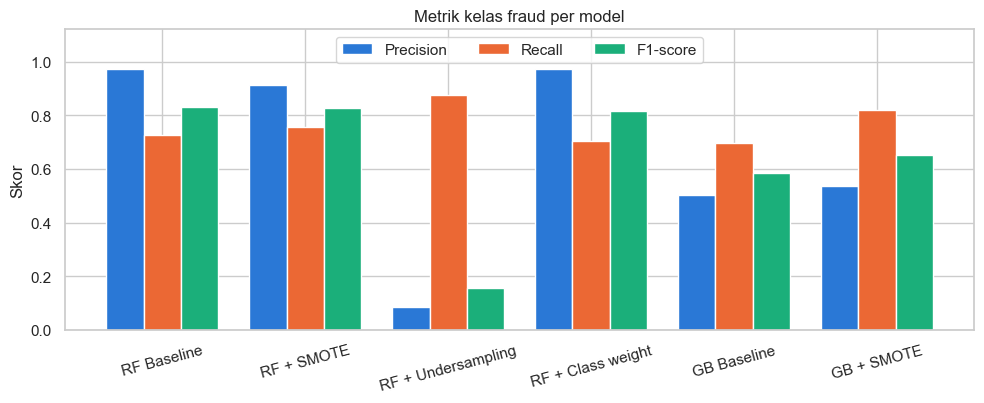

In [22]:
metrik = ["Precision", "Recall", "F1-score"]
fig, ax = plt.subplots(figsize=(10, 4.2))
posisi = np.arange(len(tabel))
lebar = 0.26
for i, (m, warna) in enumerate(zip(metrik, WARNA)):
    ax.bar(posisi + (i - 1) * lebar, tabel[m], lebar, color=warna, label=m)
ax.set_xticks(posisi, tabel.index, rotation=15)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Skor")
ax.set_title("Metrik kelas fraud per model")
ax.legend(ncol=3, loc="upper center")
plt.tight_layout()
plt.show()

### 4.5 Kenapa accuracy saja tidak cukup

In [23]:
tebak_normal = np.zeros(len(y_test), dtype=int)
acc = accuracy_score(y_test, tebak_normal)
print("Accuracy model yang selalu menebak 'normal':", round(acc, 5))
rec = recall_score(y_test, tebak_normal)
print("Recall fraud model tersebut                :", rec)

Accuracy model yang selalu menebak 'normal': 0.99833
Recall fraud model tersebut                : 0.0


Model "bodoh" yang selalu menjawab *normal* tanpa belajar apa pun sudah mendapat accuracy 99,83%, padahal tidak menangkap satu pun fraud (recall 0). Angka ini bahkan lebih tinggi dari accuracy RF + Undersampling (98,40%), yang justru menangkap fraud paling banyak. Jadi pada data dengan 99,8% kelas mayoritas, accuracy hampir seluruhnya ditentukan oleh kelas normal, dan tidak memberi informasi apa pun tentang kemampuan model mendeteksi fraud. Karena itu yang perlu dilihat adalah precision, recall, F1, dan AUPRC untuk kelas fraud.

### 4.6 Fitur paling berpengaruh

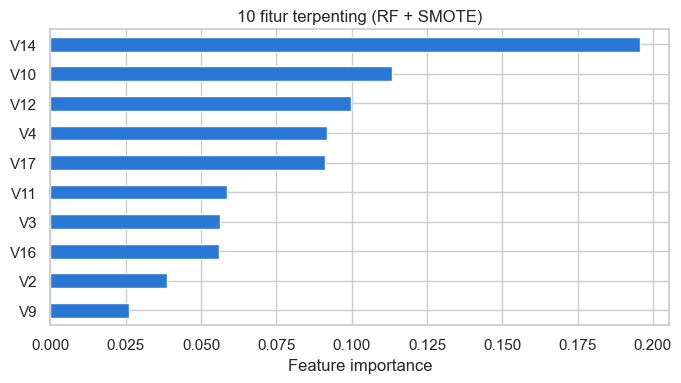

V14    0.1957
V10    0.1134
V12    0.0998
V4     0.0918
V17    0.0911
V11    0.0585
V3     0.0563
V16    0.0561
V2     0.0388
V9     0.0262
dtype: float64


In [24]:
model_smote = rf().fit(X_smote, y_smote)
importance = pd.Series(model_smote.feature_importances_,
                       index=X_train.columns).sort_values()
importance.tail(10).plot.barh(color=WARNA[0], figsize=(7, 4))
plt.title("10 fitur terpenting (RF + SMOTE)")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()
print(importance.tail(10)[::-1].round(4))

Fitur yang paling dipakai model adalah V14 (0,196), disusul V10, V12, V4, dan V17. `Amount` dan `Time` tidak masuk 10 besar, sesuai dengan temuan di bagian 2.1 bahwa nominal transaksi fraud tidak jauh berbeda dari transaksi normal.

## 5. Laporan

**Distribusi kelas awal.** Dataset berisi 284.807 transaksi dengan hanya 492 fraud (0,173%), atau sekitar 1 banding 578. Setelah 1.081 baris duplikat dihapus, tersisa 283.726 transaksi dengan 473 fraud. Data dibagi 80:20 secara stratified, sehingga data uji berisi 56.746 transaksi dengan 95 fraud.

**Pendekatan penanganan imbalance.** Ada tiga pendekatan yang dibandingkan, semuanya hanya diterapkan ke data latih:

| Pendekatan | Cara kerja | Data latih |
|---|---|---|
| SMOTE | buat fraud sintetis lewat interpolasi tetangga terdekat | 453.204 baris (50:50) |
| Random undersampling | buang transaksi normal secara acak | 756 baris (50:50) |
| Class weight | data tetap, kesalahan pada fraud diberi bobot lebih besar | 226.980 baris (asli) |

**Performa model.** Ringkasan untuk kelas fraud di data uji:

| Model | Precision | Recall | F1 | AUC-ROC | AUPRC |
|---|---|---|---|---|---|
| RF Baseline | 0,972 | 0,726 | 0,831 | 0,924 | 0,788 |
| RF + SMOTE | 0,911 | 0,758 | 0,828 | 0,966 | **0,804** |
| RF + Undersampling | 0,085 | **0,874** | 0,155 | **0,977** | 0,698 |
| RF + Class weight | 0,971 | 0,705 | 0,817 | 0,925 | 0,796 |
| GB Baseline | 0,504 | 0,695 | 0,584 | 0,765 | 0,528 |
| GB + SMOTE | 0,538 | 0,821 | 0,650 | 0,965 | 0,795 |

**Analisis.** Random Forest ternyata sudah cukup tahan terhadap imbalance meskipun tanpa penanganan apa pun, karena precision baseline-nya sangat tinggi. Masalahnya ada di recall: 26 dari 95 fraud lolos. Dari tiga pendekatan, SMOTE memberi hasil paling seimbang. Recall naik, fraud yang lolos turun dari 26 menjadi 23, dan alarm palsu hanya bertambah dari 2 menjadi 7. AUC-ROC dan AUPRC-nya juga naik. Undersampling menangkap fraud paling banyak (83 dari 95), tapi dengan 896 alarm palsu precision-nya jatuh ke 0,085, sehingga kurang praktis. Penyebabnya, model kehilangan lebih dari 99% informasi tentang transaksi normal. Class weight hampir tidak berpengaruh pada Random Forest dengan pohon yang tumbuh penuh.

Efek penanganan imbalance paling terlihat pada Gradient Boosting: dengan SMOTE, recall naik dari 0,695 ke 0,821 dan AUPRC naik sekitar 1,5 kali (0,528 ke 0,795). Meski begitu, Random Forest tetap lebih unggul dari sisi precision dan F1.

**Kesimpulan.** Untuk dataset ini, model terbaik secara keseluruhan adalah **Random Forest + SMOTE**, dengan AUPRC tertinggi (0,804) dan keseimbangan precision-recall yang paling baik. Kalau prioritasnya menangkap sebanyak mungkin fraud dan alarm palsu masih bisa ditoleransi, undersampling bisa dipertimbangkan, tapi jumlah transaksi yang harus diperiksa manual jadi jauh lebih banyak. Accuracy tidak bisa dipakai sebagai acuan: model yang selalu menebak normal pun sudah mendapat 99,83%.